In [2]:
!pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.5 MB/s eta 0:00:00


In [1]:
!nvidia-smi

Mon Oct 12 14:18:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [4]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [5]:
print(dataset["train"].features)

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


In [6]:
for i in range(10):
    review = dataset["train"][i]

    print("LABEL:", review["label"])
    print("TEXT:", review["text"][:500])
    print("-" * 80)

LABEL: 0
TEXT: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent
--------------------------------------------------------------------------------
LABEL: 0
TEXT: "I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gap

In [7]:
#count of label in training dataset
from collections import Counter

label_counts = Counter(dataset["train"]["label"])

print(label_counts)

Counter({0: 12500, 1: 12500})


In [8]:
#percentage of positive and negative output in a training dataset
total = len(dataset["train"])

for label, count in label_counts.items():
    print(
        f"Label {label}: "
        f"{count} "
        f"({count / total * 100:.2f}%)"
    )

Label 0: 12500 (50.00%)
Label 1: 12500 (50.00%)


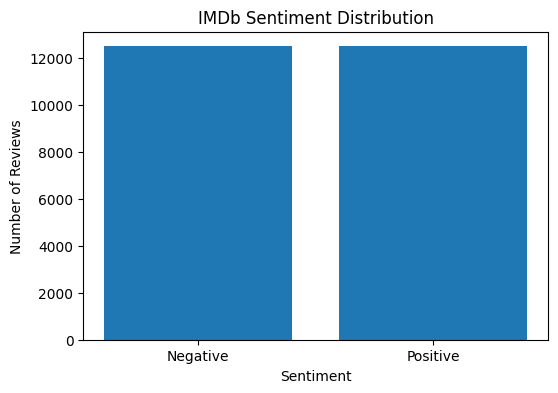

In [9]:
import matplotlib.pyplot as plt

labels = list(label_counts.keys())

counts = list(label_counts.values())

plt.figure(figsize=(6, 4))

plt.bar(
    ["Negative", "Positive"],
    counts
)

plt.title("IMDb Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [10]:
import pandas as pd

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

train_df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [11]:
train_df.shape

(25000, 2)

In [12]:
#checking missing value in training and testing dataset
print("Missing values in train:")
print(train_df.isnull().sum())

print("\nMissing values in test:")
print(test_df.isnull().sum())

Missing values in train:
text     0
label    0
dtype: int64

Missing values in test:
text     0
label    0
dtype: int64


In [13]:
#any duplicate value

print(
    "Duplicate reviews:",
    train_df["text"].duplicated().sum()
)

Duplicate reviews: 96


In [14]:
train_df["word_count"] = (
    train_df["text"]
    .str.split()
    .str.len()
)

train_df["word_count"].describe()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64

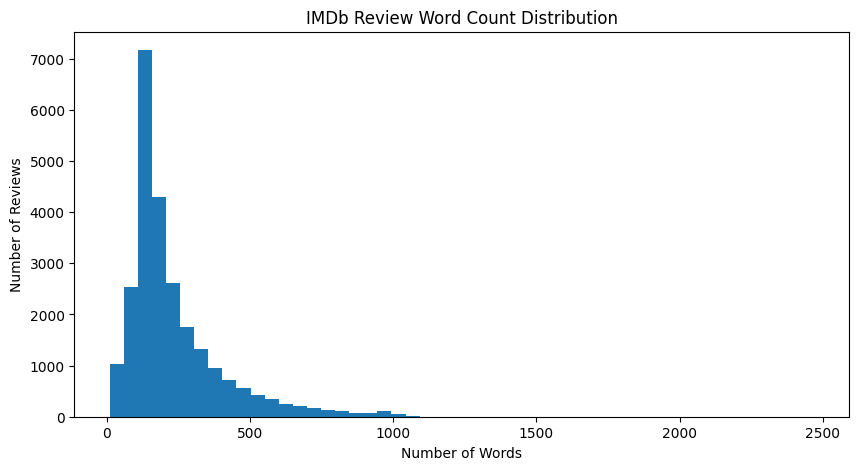

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["word_count"],
    bins=50
)

plt.title("IMDb Review Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [16]:
train_df.groupby("label")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,12500.0,230.86784,166.663126,10.0,128.0,174.0,278.0,1522.0
1,12500.0,236.70656,180.485743,12.0,125.0,174.0,291.0,2470.0


In [17]:
duplicate_texts = train_df[
    train_df["text"].duplicated(keep=False)
].sort_values("text")

duplicate_texts.head(20)

,text,label,word_count
934,'Dead Letter Office' is a low-budget film abou...,0,163
4217,'Dead Letter Office' is a low-budget film abou...,0,163
18590,".......Playing Kaddiddlehopper, Col San Fernan...",1,190
21740,".......Playing Kaddiddlehopper, Col San Fernan...",1,190
7176,"<br /><br />Back in his youth, the old man had...",0,193
7177,"<br /><br />Back in his youth, the old man had...",0,193
13261,A have a female friend who is currently being ...,1,201
13263,A have a female friend who is currently being ...,1,201
15714,"A longtime fan of Bette Midler, I must say her...",1,83
22165,"A longtime fan of Bette Midler, I must say her...",1,83


In [18]:
duplicate_texts.groupby("text")["label"].nunique().value_counts()

label
1    92
Name: count, dtype: int64

In [19]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [20]:
sample_texts = train_df["text"].sample(
    1000,
    random_state=42
)

token_lengths = [
    len(tokenizer.encode(
        text,
        add_special_tokens=True
    ))
    for text in sample_texts
]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (808 > 512). Running this sequence through the model will result in indexing errors


In [21]:
token_length_series = pd.Series(token_lengths)

print(token_length_series.describe())

count    1000.000000
mean      311.992000
std       223.927849
min        44.000000
25%       167.000000
50%       234.500000
75%       392.000000
max      1509.000000
dtype: float64


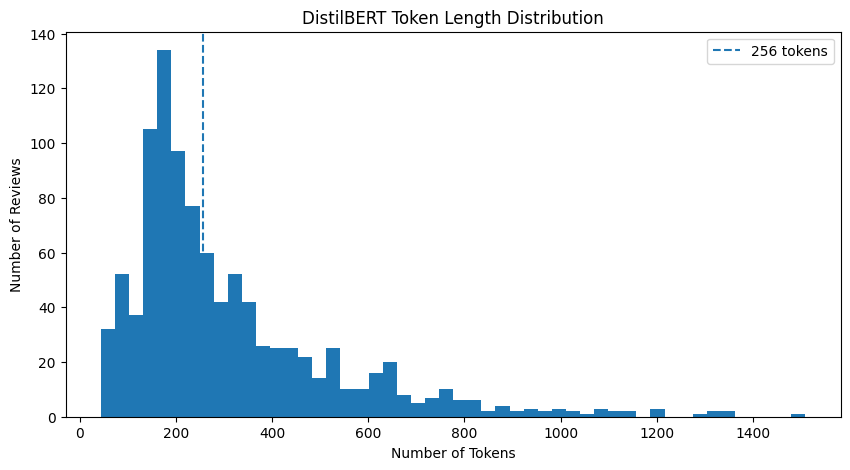

In [22]:
plt.figure(figsize=(10, 5))

plt.hist(
    token_lengths,
    bins=50
)

plt.axvline(
    256,
    linestyle="--",
    label="256 tokens"
)

plt.title("DistilBERT Token Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Reviews")

plt.legend()

plt.show()

In [23]:
above_256 = sum(
    length > 256
    for length in token_lengths
)

percentage_above_256 = (
    above_256 / len(token_lengths)
) * 100

print(
    f"Reviews above 256 tokens: "
    f"{percentage_above_256:.2f}%"
)

Reviews above 256 tokens: 44.70%


In [24]:
duplicate_texts.groupby("text")["label"].nunique().value_counts()


label
1    92
Name: count, dtype: int64

In [25]:
print(token_length_series.describe())
print(f"{percentage_above_256:.2f}%")

count    1000.000000
mean      311.992000
std       223.927849
min        44.000000
25%       167.000000
50%       234.500000
75%       392.000000
max      1509.000000
dtype: float64
44.70%


In [26]:
train_texts = set(dataset["train"]["text"])
test_texts = set(dataset["test"]["text"])

overlap = train_texts.intersection(test_texts)

print("Train/Test duplicate overlap:", len(overlap))

Train/Test duplicate overlap: 123


In [27]:
clean_train = dataset["train"].filter(
    lambda example: example["text"] not in overlap
)

print("Original train size:", len(dataset["train"]))
print("Clean train size:", len(clean_train))

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Original train size: 25000
Clean train size: 24877


In [28]:
clean_train_texts = set(clean_train["text"])

remaining_overlap = clean_train_texts.intersection(
    test_texts
)

print(
    "Remaining train/test overlap:",
    len(remaining_overlap)
)

Remaining train/test overlap: 0


In [29]:
train_validation = clean_train.train_test_split(
    test_size=0.1,
    seed=42
)

In [30]:
from datasets import DatasetDict
final_dataset = DatasetDict({
    "train": train_validation["train"],
    "validation": train_validation["test"],
    "test": dataset["test"]
})

print(final_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 22389
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2488
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
})


In [31]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

In [32]:
text = "I really enjoyed this movie!"

tokens = tokenizer.tokenize(text)

print(tokens)

['i', 'really', 'enjoyed', 'this', 'movie', '!']


In [33]:
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print(token_ids)

[1045, 2428, 5632, 2023, 3185, 999]


In [34]:
encoded = tokenizer(
    text
)

print(encoded)

{'input_ids': [101, 1045, 2428, 5632, 2023, 3185, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [35]:
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"]
))

['[CLS]', 'i', 'really', 'enjoyed', 'this', 'movie', '!', '[SEP]']


In [36]:
def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=256
    )

In [37]:
tokenized_dataset = final_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/22389 [00:00<?, ? examples/s]

Map:   0%|          | 0/2488 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [38]:
print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 22389
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2488
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
})


In [39]:
#check out the sample of training data
sample = tokenized_dataset["train"][0]

print("Input IDs:")
print(sample["input_ids"][:30])

print("\nAttention Mask:")
print(sample["attention_mask"][:30])

print("\nLabel:")
print(sample["label"])

Input IDs:
[101, 2137, 12696, 2888, 13545, 2050, 17509, 1000, 11552, 1000, 2198, 4922, 1010, 2019, 12520, 4744, 2121, 2040, 2038, 2018, 2010, 11419, 2502, 19838, 1000, 10508, 1000, 16360, 15094, 23656]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Label:
1


In [40]:
# padding lookup

short_text = "This movie was great!"

encoded_short = tokenizer(
    short_text,
    padding="max_length",
    truncation=True,
    max_length=20
)

print(
    tokenizer.convert_ids_to_tokens(
        encoded_short["input_ids"]
    )
)

print(encoded_short["attention_mask"])

['[CLS]', 'this', 'movie', 'was', 'great', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [41]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [42]:
import torch

sample = tokenized_dataset["train"][0]

input_ids = torch.tensor(
    [sample["input_ids"]]
)

attention_mask = torch.tensor(
    [sample["attention_mask"]]
)

with torch.no_grad():

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print(outputs.logits)

tensor([[-0.2029, -0.1133]])


In [43]:
print(outputs.logits.shape)

torch.Size([1, 2])


In [44]:
probabilities = torch.softmax(
    outputs.logits,
    dim=-1
)

print(probabilities)

tensor([[0.4776, 0.5224]])


In [45]:
prediction = torch.argmax(
    probabilities,
    dim=-1
)

print(prediction)

tensor([1])


In [46]:
# measurement of baseline performance before fine tuning

from sklearn.metrics import accuracy_score

predictions = []
true_labels = []

for example in tokenized_dataset["validation"]:

    inputs = {
        "input_ids": torch.tensor(
            [example["input_ids"]]
        ),
        "attention_mask": torch.tensor(
            [example["attention_mask"]]
        )
    }

    with torch.no_grad():

        outputs = model(**inputs)

    prediction = torch.argmax(
        outputs.logits,
        dim=-1
    ).item()

    predictions.append(prediction)
    true_labels.append(example["label"])

In [47]:
accuracy = accuracy_score(
    true_labels,
    predictions
)

print("Baseline accuracy:", accuracy)

Baseline accuracy: 0.5008038585209004


In [48]:
import torch
import torch.nn.functional as F

# Example: positive review
true_label = torch.tensor([1])

# Your model's logits
logits = torch.tensor([[0.1070, 0.1055]])

loss = F.cross_entropy(logits, true_label)

print("Loss:", loss.item())

Loss: 0.6938974261283875


In [49]:
print(dataset["train"].features["label"])

ClassLabel(names=['neg', 'pos'])


In [50]:
print(tokenized_dataset.keys())

dict_keys(['train', 'validation', 'test'])


In [51]:
print(tokenized_dataset["train"].column_names)

['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [52]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [53]:
import transformers

print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

Transformers version: 5.16.1
GPU available: True


In [54]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert-imdb-results",

    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,

    logging_steps=100,
    report_to="none",

    fp16=True,
    seed=42
)

In [55]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

In [56]:
train_result = trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.530424,0.497894,0.895096,0.930070,0.854618,0.890749
2,0.405259,0.629488,0.911174,0.905705,0.918072,0.911847


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [57]:
eval_results = trainer.evaluate()

print(eval_results)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.405259,0.629488,2,0.911174,0.905705,0.918072,0.911847


{'eval_loss': 0.629488468170166, 'eval_accuracy': 0.9111736334405145, 'eval_precision': 0.9057052297939778, 'eval_recall': 0.9180722891566265, 'eval_f1': 0.9118468288791384}


In [58]:
test_results = trainer.evaluate(
    eval_dataset=tokenized_dataset["test"],
    metric_key_prefix="test"
)

for metric, value in test_results.items():
    print(f"{metric}: {value}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.405259,0.594262,2,0.911440,0.906048,0.918080,0.912024


test_loss: 0.5942621231079102
test_accuracy: 0.91144
test_precision: 0.9060476867203537
test_recall: 0.91808
test_f1: 0.9120241595803862


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


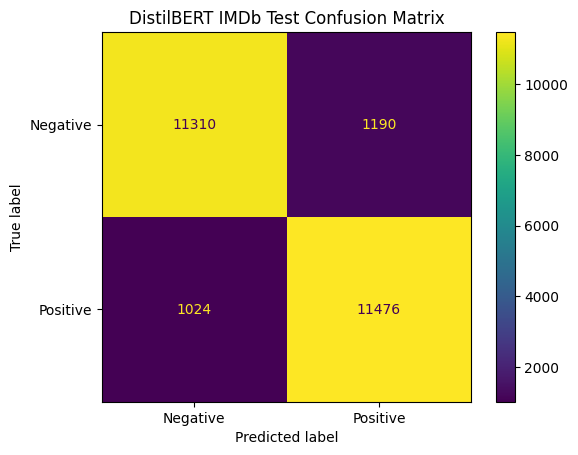

              precision    recall  f1-score   support

    Negative     0.9170    0.9048    0.9108     12500
    Positive     0.9060    0.9181    0.9120     12500

    accuracy                         0.9114     25000
   macro avg     0.9115    0.9114    0.9114     25000
weighted avg     0.9115    0.9114    0.9114     25000



In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Generate predictions on the test set
pred_output = trainer.predict(tokenized_dataset["test"])

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(values_format="d")
plt.title("DistilBERT IMDb Test Confusion Matrix")
plt.show()

# Detailed classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"],
    digits=4
))

In [60]:
import pandas as pd
import numpy as np

test_df = pd.DataFrame({
    "text": dataset["test"]["text"],
    "true_label": y_true,
    "predicted_label": y_pred
})

test_df["true_sentiment"] = test_df["true_label"].map({
    0: "Negative",
    1: "Positive"
})

test_df["predicted_sentiment"] = test_df["predicted_label"].map({
    0: "Negative",
    1: "Positive"
})

errors = test_df[
    test_df["true_label"] != test_df["predicted_label"]
]

print("Total incorrect predictions:", len(errors))

errors[
    ["text", "true_sentiment", "predicted_sentiment"]
].head(10)

Total incorrect predictions: 2214


,text,true_sentiment,predicted_sentiment
4,"First off let me say, If you haven't enjoyed a...",Negative,Positive
18,"Ben, (Rupert Grint), is a deeply unhappy adole...",Negative,Positive
20,Low budget horror movie. If you don't raise yo...,Negative,Positive
32,I'm the type of guy who loves hood movies from...,Negative,Positive
37,The only reason this movie is not given a 1 (a...,Negative,Positive
46,"Okay, so it was never going to change the worl...",Negative,Positive
56,There are many different versions of this one ...,Negative,Positive
61,This film features two of my favorite guilty p...,Negative,Positive
73,"1983's ""Frightmare"" is an odd little film. The...",Negative,Positive
86,The film opens with a cult leader attempting t...,Negative,Positive


In [61]:
# False positives: actual Negative, predicted Positive
false_positives = test_df[
    (test_df["true_label"] == 0) &
    (test_df["predicted_label"] == 1)
]

# False negatives: actual Positive, predicted Negative
false_negatives = test_df[
    (test_df["true_label"] == 1) &
    (test_df["predicted_label"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

False positives: 1190
False negatives: 1024


In [62]:
import torch
import numpy as np

logits = pred_output.predictions

probabilities = torch.softmax(
    torch.tensor(logits),
    dim=1
).numpy()

test_df["negative_probability"] = probabilities[:, 0]
test_df["positive_probability"] = probabilities[:, 1]

test_df["confidence"] = probabilities.max(axis=1)

test_df["is_correct"] = (
    test_df["true_label"] == test_df["predicted_label"]
)

# Most confident incorrect predictions
confident_errors = test_df[
    ~test_df["is_correct"]
].sort_values(
    "confidence",
    ascending=False
)

confident_errors[
    [
        "text",
        "true_sentiment",
        "predicted_sentiment",
        "confidence"
    ]
].head(10)

,text,true_sentiment,predicted_sentiment,confidence
12061,This movie was pure genius. John Waters is bri...,Negative,Positive,0.998435
2160,There are those who gripe that this is NOT the...,Negative,Positive,0.998411
4118,This is definitely one of the best Kung fu mov...,Negative,Positive,0.998389
7110,This is one entertaining flick. I suggest you ...,Negative,Positive,0.998370
7109,"This has to be one of, if not THE greatest Mob...",Negative,Positive,0.998301
11707,This has to be one of the all time greatest ho...,Negative,Positive,0.998250
2688,I really liked this quirky movie. The characte...,Negative,Positive,0.998209
5820,I saw Winnie's Heffalump a couple of days ago....,Negative,Positive,0.998189
8782,"Yes,the movie is not a piece of art but the fi...",Negative,Positive,0.998167
11770,"Based on the comments made so far, everyone se...",Negative,Positive,0.998158


In [63]:
# Inspect the complete text of the 5 most confident errors
for idx, row in confident_errors.head(5).iterrows():
    print("=" * 100)
    print("Test index:", idx)
    print("True sentiment:", row["true_sentiment"])
    print("Predicted sentiment:", row["predicted_sentiment"])
    print("Confidence:", round(row["confidence"], 6))
    print("Negative probability:", round(row["negative_probability"], 6))
    print("Positive probability:", round(row["positive_probability"], 6))
    print("\nFULL REVIEW:\n")
    print(row["text"])
    print()

Test index: 12061
True sentiment: Negative
Predicted sentiment: Positive
Confidence: 0.998435
Negative probability: 0.001565
Positive probability: 0.998435

FULL REVIEW:

This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's movies, this is probably my favorite. I give it 9.5/10. Rent it today!

Test index: 2160
True sentiment: Negative
Predicted sentiment: Positive
Confidence: 0.998411
Negative probability: 0.001589
Positive probability: 0.998411

FULL REVIEW:

There are those who gripe that this is NOT the opera, but then they don't quibble with the film of CABARET that was not the original show either. All films of musicals/operas are and have to be "adaptations" or they don't work. CABARET took m

In [64]:
# Check whether the text and labels are aligned
test_split = tokenized_dataset["test"]

print(
    "Text order matches:",
    all(
        dataset["test"][i]["text"] == test_split[i]["text"]
        for i in range(len(test_split))
    )
)

print(
    "Labels match:",
    np.array_equal(
        np.array(test_split["label"]),
        y_true
    )
)

# Inspect the first five suspicious examples directly
for idx in confident_errors.head(5).index:
    print("\nTest index:", idx)
    print("Original label:", dataset["test"][int(idx)]["label"])
    print("Tokenized label:", test_split[int(idx)]["label"])
    print("Prediction label:", int(y_pred[int(idx)]))
    print("Review:", test_split[int(idx)]["text"][:200])

Text order matches: True
Labels match: True

Test index: 12061
Original label: 0
Tokenized label: 0
Prediction label: 1
Review: This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Rick

Test index: 2160
Original label: 0
Tokenized label: 0
Prediction label: 1
Review: There are those who gripe that this is NOT the opera, but then they don't quibble with the film of CABARET that was not the original show either. All films of musicals/operas are and have to be "adapt

Test index: 4118
Original label: 0
Tokenized label: 0
Prediction label: 1
Review: This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one 

Test index: 7110
Original label: 0
Tokenized label: 0
Prediction label: 1
Review: This is one entertai

In [65]:
train_texts = set(clean_train["text"])
test_texts = set(dataset["test"]["text"])

remaining_overlap = train_texts.intersection(test_texts)

print("Remaining exact train-test overlaps:", len(remaining_overlap))

for idx in confident_errors.head(10).index:
    review = dataset["test"][int(idx)]["text"]

    print(
        f"Test index {idx}:",
        "Overlap" if review in remaining_overlap else "No overlap"
    )

Remaining exact train-test overlaps: 0
Test index 12061: No overlap
Test index 2160: No overlap
Test index 4118: No overlap
Test index 7110: No overlap
Test index 7109: No overlap
Test index 11707: No overlap
Test index 2688: No overlap
Test index 5820: No overlap
Test index 8782: No overlap
Test index 11770: No overlap


In [66]:
import numpy as np

# Calculate token lengths before truncation
sample_size = min(1000, len(dataset["test"]))
sample_texts = dataset["test"].select(
    range(sample_size)
)["text"]

lengths = [
    len(tokenizer(
        text,
        truncation=False,
        add_special_tokens=True
    )["input_ids"])
    for text in sample_texts
]

print("Sample size:", sample_size)
print("Mean token length:", round(np.mean(lengths), 2))
print("Median token length:", round(np.median(lengths), 2))
print("Percentage above 256 tokens:",
      round(np.mean(np.array(lengths) > 256) * 100, 2), "%")
print("Percentage above 512 tokens:",
      round(np.mean(np.array(lengths) > 512) * 100, 2), "%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


Sample size: 1000
Mean token length: 309.37
Median token length: 240.0
Percentage above 256 tokens: 46.0 %
Percentage above 512 tokens: 14.1 %


In [67]:

# Step 1: Tokenize reviews with a maximum length of 512

from transformers import AutoTokenizer, DataCollatorWithPadding

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function_512(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=512
    )

tokenized_dataset_512 = final_dataset.map(
    tokenize_function_512,
    batched=True,
    remove_columns=["text"]
)

# Pad each batch dynamically instead of padding every review to 512
data_collator_512 = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print(tokenized_dataset_512)
print("\nTraining example token length:",
      len(tokenized_dataset_512["train"][0]["input_ids"]))
print("Validation examples:",
      len(tokenized_dataset_512["validation"]))
print("Test examples:",
      len(tokenized_dataset_512["test"]))

Map:   0%|          | 0/22389 [00:00<?, ? examples/s]

Map:   0%|          | 0/2488 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 22389
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2488
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
})

Training example token length: 417
Validation examples: 2488
Test examples: 25000


In [68]:

from transformers import AutoModelForSequenceClassification

model_512 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("New 512-token model created.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


New 512-token model created.


In [70]:

from transformers import TrainingArguments, Trainer

training_args_512 = TrainingArguments(
    output_dir="./distilbert-imdb-512-results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=100,
    report_to="none",
    fp16=True,
    seed=42
)

trainer_512 = Trainer(
    model=model_512,
    args=training_args_512,
    train_dataset=tokenized_dataset_512["train"],
    eval_dataset=tokenized_dataset_512["validation"],
    processing_class=tokenizer,
    data_collator=data_collator_512,
    compute_metrics=compute_metrics
)

print("Trainer configured for 512-token experiment.")

Trainer configured for 512-token experiment.


In [71]:

train_result_512 = trainer_512.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.495821,0.451635,0.913987,0.947095,0.877108,0.910759
2,0.355440,0.509351,0.928055,0.929839,0.926104,0.927968


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [72]:

validation_results_512 = trainer_512.evaluate(
    eval_dataset=tokenized_dataset_512["validation"]
)

print("\n512-token Validation Results")
for metric, value in validation_results_512.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.355440,0.509351,2,0.928055,0.929839,0.926104,0.927968



512-token Validation Results
eval_loss: 0.5094
eval_accuracy: 0.9281
eval_precision: 0.9298
eval_recall: 0.9261
eval_f1: 0.9280


In [73]:

print("Best checkpoint:", trainer_512.state.best_model_checkpoint)
print("Best validation F1:", trainer_512.state.best_metric)

best_validation_results_512 = trainer_512.evaluate(
    eval_dataset=tokenized_dataset_512["validation"]
)

for metric, value in best_validation_results_512.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Best checkpoint: ./distilbert-imdb-512-results/checkpoint-2800
Best validation F1: 0.9279678068410463


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.355440,0.509351,2,0.928055,0.929839,0.926104,0.927968


eval_loss: 0.5094
eval_accuracy: 0.9281
eval_precision: 0.9298
eval_recall: 0.9261
eval_f1: 0.9280


In [74]:

import os

save_directory = "./sentiment-distilbert-512"

# Save the fine-tuned model and tokenizer
trainer_512.save_model(save_directory)
tokenizer.save_pretrained(save_directory)

print("Model saved to:", os.path.abspath(save_directory))
print("Saved files:")
print(os.listdir(save_directory))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /kaggle/working/sentiment-distilbert-512
Saved files:
['config.json', 'model.safetensors', 'training_args.bin', 'tokenizer_config.json', 'tokenizer.json']


In [77]:
import shutil

shutil.make_archive(
    "/kaggle/working/sentiment-distilbert-512",
    "zip",
    "/kaggle/working/sentiment-distilbert-512"
)

'/kaggle/working/sentiment-distilbert-512.zip'

In [80]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/sentiment-distilbert-512.zip"))

/kaggle/working/sentiment-distilbert-512.zip

In [81]:
import shutil
from IPython.display import FileLink, display

shutil.make_archive(
    "/kaggle/working/all_files",
    "zip",
    "/kaggle/working"
)

display(FileLink("/kaggle/working/all_files.zip"))

KeyboardInterrupt: 

In [82]:

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

model_path = "./sentiment-distilbert-512"

loaded_tokenizer = AutoTokenizer.from_pretrained(model_path)
loaded_model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

loaded_model.to(device)
loaded_model.eval()

def predict_sentiment(review):
    inputs = loaded_tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = loaded_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_id = int(torch.argmax(probabilities).item())

    labels = ["Negative", "Positive"]

    return {
        "sentiment": labels[predicted_id],
        "confidence": round(float(probabilities[predicted_id].item()), 4)
    }

review = "The acting was brilliant and the story kept me engaged throughout."
print(predict_sentiment(review))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'sentiment': 'Positive', 'confidence': 0.9963}
